In [9]:
import pandas as pd
df = pd.read_csv("listings.csv", compression=None)

In [15]:
import pandas as pd
import sqlite3

conn = sqlite3.connect("airbnb.db")

def run(query):
    return pd.read_sql_query(query, conn)

In [1]:
import os
print(os.getcwd())
print(os.listdir(".."))
print(os.listdir("../data"))

/Users/rakshith/Desktop/berlin-airbnb-analysis./Data
['.DS_Store', 'images', 'Untitled.ipynb', '.ipynb_checkpoints', 'Data', 'notebooks', 'sql']
['listings.csv.gz', 'calendar.csv.gz', 'Untitled1.ipynb', 'Untitled.ipynb', 'reviews.csv.gz', '.ipynb_checkpoints']


In [3]:
import os
for f in ["listings.csv.gz", "calendar.csv.gz", "reviews.csv.gz"]:
    print(f, os.path.getsize(f), "bytes")

with open("listings.csv.gz", "rb") as file:
    print(file.read(150))

listings.csv.gz 31425598 bytes
calendar.csv.gz 153315081 bytes
reviews.csv.gz 198537449 bytes
b'id,listing_url,scrape_id,last_scraped,source,name,description,neighborhood_overview,picture_url,host_id,host_url,host_profile_id,host_profile_url,host'


In [4]:
import pandas as pd
df = pd.read_csv("listings.csv.gz", compression=None)
print(df.shape)
df[["neighbourhood_cleansed", "room_type", "price"]].head()

(12376, 90)


,neighbourhood_cleansed,room_type,price
0,Grunewald,Entire home/apt,$97.00
1,Grunewald,Entire home/apt,$69.60
2,Rixdorf,Entire home/apt,$219.00
3,südliche Luisenstadt,Private room,NaN
4,Rixdorf,Private room,NaN


In [3]:
import pandas as pd
df = pd.read_csv("listings.csv")
print(df.shape)

(12376, 90)


In [12]:
cols = ["id", "name", "host_id", "neighbourhood_cleansed", "room_type",
        "accommodates", "bedrooms", "price", "minimum_nights",
        "availability_365", "number_of_reviews", "review_scores_rating"]
df = df[cols]
df[["neighbourhood_cleansed", "room_type", "price"]].head()

,neighbourhood_cleansed,room_type,price
0,Grunewald,Entire home/apt,$97.00
1,Grunewald,Entire home/apt,$69.60
2,Rixdorf,Entire home/apt,$219.00
3,südliche Luisenstadt,Private room,NaN
4,Rixdorf,Private room,NaN


In [5]:
df["price"] = df["price"].str.replace("$", "", regex=False).str.replace(",", "", regex=False).astype(float)
df["price"].describe()

count     8157.000000
mean       167.564032
std        191.783955
min         12.860000
25%         81.140000
50%        129.500000
75%        203.000000
max      10025.000000
Name: price, dtype: float64

In [6]:
df.isnull().sum()

id                           0
name                         0
host_id                      0
neighbourhood_cleansed       0
room_type                    0
accommodates                 0
bedrooms                    13
price                     4219
minimum_nights             143
availability_365             0
number_of_reviews            0
review_scores_rating      2237
dtype: int64

In [7]:
df[df["review_scores_rating"].isnull()]["number_of_reviews"].describe()

count    2237.0
mean        0.0
std         0.0
min         0.0
25%         0.0
50%         0.0
75%         0.0
max         0.0
Name: number_of_reviews, dtype: float64

# Notes: Exploring the Data

**Size**
- The listings file has 12,376 rows (one row per Airbnb listing in Berlin).
- I kept 12 columns that matter for the analysis: id, name, host_id, neighbourhood, room type, guests, bedrooms, price, minimum nights, availability, number of reviews, and review score.

**Price column**
- Price was stored as text (like "$97.00"), so I removed the "$" and commas and changed it to a number.
- Only 8,157 listings have a price. The other 4,219 (34%) are missing.
- Lowest price: 12.86. Median: 129.50. Average: 167.56. Highest: 10,025.
- The average is well above the median, and the highest price is far above the rest. This means a few extreme prices pull the average up, so I will look for outliers before analyzing prices.

**Missing values**
- price: 4,219 (34%)
- review_scores_rating: 2,237 (18%). Most of these are likely listings with no reviews yet.
- minimum_nights: 143 (1%)
- bedrooms: 13 (0.1%)
- All other columns have no missing values.


In [8]:
print(df.duplicated(subset="id").sum())

0


In [9]:
before = len(df)
df = df.dropna(subset=["price"]).copy()
print(before, "->", len(df))

12376 -> 8157


In [10]:
print(df["price"].quantile([0.01, 0.50, 0.95, 0.99]))
print(df.sort_values("price", ascending=False)[["price", "room_type", "accommodates"]].head(10))

0.01     26.304
0.50    129.500
0.95    392.534
0.99    691.200
Name: price, dtype: float64
          price        room_type  accommodates
7928   10025.00  Entire home/apt             7
6031    4457.70  Entire home/apt            16
573     3837.63  Entire home/apt             2
1027    2956.00  Entire home/apt            15
6098    2296.00  Entire home/apt            16
1961    2270.40  Entire home/apt            12
6130    2262.00  Entire home/apt            16
7491    2100.00  Entire home/apt            12
11361   2033.33  Entire home/apt             6
2233    1995.00  Entire home/apt             6


In [11]:
cap = df["price"].quantile(0.99)
before = len(df)
df = df[(df["price"] >= 15) & (df["price"] <= cap)].copy()
print("cap:", cap, "| removed:", before - len(df))
df["price"].describe()

cap: 691.199999999998 | removed: 85


count    8072.000000
mean      156.706939
std       106.286199
min        15.000000
25%        80.937500
50%       128.000000
75%       200.000000
max       689.000000
Name: price, dtype: float64

In [12]:
df["bedrooms"] = df["bedrooms"].fillna(df["bedrooms"].median())
df["minimum_nights"] = df["minimum_nights"].fillna(df["minimum_nights"].median())
df["has_reviews"] = df["number_of_reviews"] > 0
df.isnull().sum()

id                           0
name                         0
host_id                      0
neighbourhood_cleansed       0
room_type                    0
accommodates                 0
bedrooms                     0
price                        0
minimum_nights               0
availability_365             0
number_of_reviews            0
review_scores_rating      1252
has_reviews                  0
dtype: int64

In [13]:
df.to_csv("listings_clean.csv", index=False)
print(df.shape)

(8072, 13)


## Notes: Cleaning Decisions

- Duplicates: [0].
- Removed 4,219 listings with no price (34% of the file), because price is the main thing I am studying. This is a limit: listings without a price may differ from the rest.
- Removed 85 outliers: prices under 15 and the top 1% of prices (above 691). A few extreme prices were pulling the average up.
- Average price after cleaning: 156.71 (before: 167.56). Median: 128.00. The average is still above the median, so a few expensive listings still pull it up. I will use the median when comparing neighborhoods.
- Filled the few missing bedrooms and minimum nights values with the median.
- Left review scores empty (1,252 listings, 16%) for listings with no reviews yet, and added a has_reviews column.
- Final clean dataset: 8,072 rows and 13 columns, saved as listings_clean.csv.

In [14]:
print((~df["has_reviews"]).sum())

1252


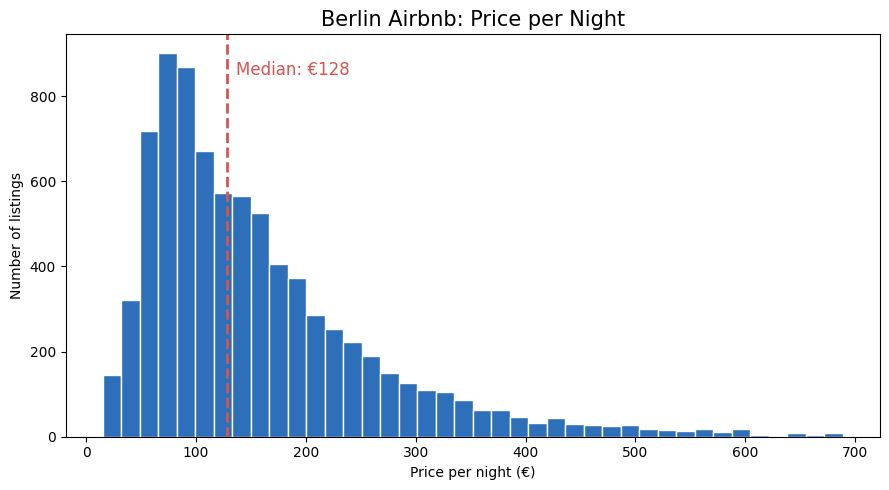

In [15]:
import matplotlib.pyplot as plt

median = df["price"].median()

plt.figure(figsize=(9, 5))
plt.hist(df["price"], bins=40, color="#2E6FBA", edgecolor="white")
plt.axvline(median, color="#D9534F", linestyle="--", linewidth=2)
plt.text(median + 8, plt.ylim()[1] * 0.9, f"Median: €{median:.0f}", color="#D9534F", fontsize=12)
plt.title("Berlin Airbnb: Price per Night", fontsize=15)
plt.xlabel("Price per night (€)")
plt.ylabel("Number of listings")
plt.tight_layout()
plt.savefig("../images/price_distribution.png", dpi=200)
plt.show()

In [16]:
import pandas as pd
import sqlite3

df = pd.read_csv("listings_clean.csv")
conn = sqlite3.connect("airbnb.db")
df.to_sql("listings", conn, if_exists="replace", index=False)
print("rows loaded:", len(df))

rows loaded: 8072


In [17]:
def run(query):
    return pd.read_sql_query(query, conn)

#Query 1, listings by room type

In [18]:
q1 = """
SELECT room_type,
       COUNT(*) AS listings,
       ROUND(AVG(price), 2) AS avg_price
FROM listings
GROUP BY room_type
ORDER BY listings DESC;
"""
run(q1)

,room_type,listings,avg_price
0,Entire home/apt,5796,179.55
1,Private room,2147,98.51
2,Shared room,76,42.91
3,Hotel room,53,179.10


#Query 2, price by neighborhood

In [19]:
q2 = """
SELECT neighbourhood_cleansed AS neighbourhood,
       COUNT(*) AS listings,
       ROUND(AVG(price), 2) AS avg_price
FROM listings
GROUP BY neighbourhood_cleansed
HAVING COUNT(*) >= 30
ORDER BY avg_price DESC;
"""
run(q2)

,neighbourhood,listings,avg_price
0,Regierungsviertel,96,207.01
1,Brunnenstr. Nord,183,205.26
2,Prenzlauer Berg Südwest,242,203.27
3,Brunnenstr. Süd,331,202.85
4,Rummelsburger Bucht,35,195.49
5,Helmholtzplatz,131,187.55
6,Pankow Zentrum,50,180.38
7,Kurfürstendamm,137,177.34
8,Neue Kantstraße,93,176.10
9,Alexanderplatz,661,174.70


#Query 3, price by number of guests

In [20]:
q3 = """
SELECT accommodates AS guests,
       COUNT(*) AS listings,
       ROUND(AVG(price), 2) AS avg_price
FROM listings
GROUP BY accommodates
HAVING COUNT(*) >= 30
ORDER BY accommodates;
"""
run(q3)

,guests,listings,avg_price
0,1,675,77.72
1,2,3311,116.54
2,3,920,137.21
3,4,1560,180.56
4,5,387,219.06
5,6,645,240.35
6,7,121,288.88
7,8,206,295.01
8,9,62,285.51
9,10,66,338.40


In [21]:
with open("../sql/01_basic_queries.sql", "w") as f:
    f.write("-- Query 1: listings by room type\n" + q1 + "\n")
    f.write("-- Query 2: price by neighborhood\n" + q2 + "\n")
    f.write("-- Query 3: price by number of guests\n" + q3 + "\n")

## Notes: First SQL Queries

- Loaded the clean file (8,072 listings) into a SQLite database.
- Query 1: Entire homes are the biggest group (5,796 listings, 72%) with an average price of 179.55. Private rooms are next (2,147 listings, 27%) at 98.51. Shared rooms (76) and hotel rooms (53) are very few, so I will focus on the first two.
- Query 2: I compared 58 neighborhoods with at least 30 listings. Prices range from 78.34 (Ost 2) to 207.01 (Regierungsviertel). The most expensive areas are central ones like Regierungsviertel, Brunnenstr. Nord and Prenzlauer Berg Südwest (all above 200). The cheapest are further out, like Rudow and Zehlendorf Nord. The biggest market is Alexanderplatz with 661 listings at 174.70.
- Query 3: Price goes up with the number of guests, from 77.72 for 1 guest to 355.45 for 12 guests. Most listings are for 2 guests (3,311) and 4 guests (1,560).
- Note: these are averages, which are pulled up by expensive listings. Later I will also check medians. A high price does not mean high income

In [1]:
import pandas as pd
import sqlite3

conn = sqlite3.connect("airbnb.db")

def run(query):
    return pd.read_sql_query(query, conn)

run("SELECT COUNT(*) AS listings FROM listings")

,listings
0,8072


In [3]:
ids = set(pd.read_sql_query("SELECT id FROM listings", conn)["id"])

conn.execute("DROP TABLE IF EXISTS calendar")
total = 0
for chunk in pd.read_csv("calendar.csv", compression=None,
                         usecols=["listing_id", "date", "available"],
                         chunksize=500000):
    chunk = chunk[chunk["listing_id"].isin(ids)]
    chunk.to_sql("calendar", conn, if_exists="append", index=False)
    total += len(chunk)
print("done, rows loaded:", total)

done, rows loaded: 2946283


Query 4, how much do the top 10% earn? (uses a CTE)
We estimate each listing’s income as price times booked nights, where booked nights = 365 minus the days it is available.

In [4]:
q4 = """
WITH revenue AS (
    SELECT id, neighbourhood_cleansed, room_type, price,
           365 - availability_365 AS booked_nights,
           price * (365 - availability_365) AS est_revenue
    FROM listings
),
ranked AS (
    SELECT *, NTILE(10) OVER (ORDER BY est_revenue DESC) AS tier
    FROM revenue
)
SELECT tier,
       COUNT(*) AS listings,
       ROUND(AVG(price), 2) AS avg_price,
       ROUND(AVG(booked_nights)) AS avg_booked_nights,
       ROUND(SUM(est_revenue)) AS total_revenue,
       ROUND(100.0 * SUM(est_revenue) / (SELECT SUM(est_revenue) FROM revenue), 1) AS pct_of_all_revenue
FROM ranked
GROUP BY tier
ORDER BY tier;
"""
run(q4)

,tier,listings,avg_price,avg_booked_nights,total_revenue,pct_of_all_revenue
0,1,808,297.18,300.0,69109143.0,39.1
1,2,808,182.29,270.0,35823431.0,20.2
2,3,807,152.51,244.0,24135890.0,13.6
3,4,807,143.05,202.0,17283861.0,9.8
4,5,807,152.85,143.0,12035793.0,6.8
5,6,807,146.17,98.0,8033841.0,4.5
6,7,807,141.23,70.0,5427284.0,3.1
7,8,807,130.58,50.0,3375665.0,1.9
8,9,807,129.22,21.0,1497037.0,0.8
9,10,807,91.78,3.0,196921.0,0.1


Query 5, which room types and neighborhoods are in the top 10%?

In [5]:
q5 = """
WITH revenue AS (
    SELECT id, neighbourhood_cleansed, room_type, price,
           price * (365 - availability_365) AS est_revenue
    FROM listings
),
ranked AS (
    SELECT *, NTILE(10) OVER (ORDER BY est_revenue DESC) AS tier
    FROM revenue
)
SELECT neighbourhood_cleansed AS neighbourhood,
       COUNT(*) AS top_listings,
       ROUND(AVG(est_revenue)) AS avg_revenue
FROM ranked
WHERE tier = 1
GROUP BY neighbourhood_cleansed
HAVING COUNT(*) >= 10
ORDER BY top_listings DESC
LIMIT 10;
"""
run(q5)

,neighbourhood,top_listings,avg_revenue
0,Alexanderplatz,112,90914.0
1,Brunnenstr. Süd,52,85904.0
2,Brunnenstr. Nord,49,97826.0
3,Prenzlauer Berg Südwest,38,90313.0
4,Frankfurter Allee Süd FK,28,84572.0
5,Tempelhofer Vorstadt,25,84615.0
6,Regierungsviertel,24,91145.0
7,Prenzlauer Berg Nordwest,19,80736.0
8,Kurfürstendamm,19,94322.0
9,Reuterstraße,17,78989.0


Query 6, demand by month

In [6]:
q6 = """
SELECT strftime('%Y-%m', date) AS month,
       COUNT(*) AS listing_days,
       ROUND(100.0 * SUM(CASE WHEN available = 'f' THEN 1 ELSE 0 END) / COUNT(*), 1) AS pct_unavailable
FROM calendar
GROUP BY month
ORDER BY month;
"""
run(q6)

,month,listing_days,pct_unavailable
0,2026-09,89217,73.0
1,2026-10,250232,47.2
2,2026-11,242160,33.5
3,2026-12,250232,31.0
4,2027-01,250232,27.6
5,2027-02,226016,27.3
6,2027-03,250232,29.8
7,2027-04,242160,34.7
8,2027-05,250232,34.4
9,2027-06,242160,37.8


In [7]:
with open("../sql/02_revenue_and_demand.sql", "w") as f:
    f.write("-- Query 4: income share by tier (CTE + NTILE)\n" + q4 + "\n")
    f.write("-- Query 5: neighborhoods in the top 10%\n" + q5 + "\n")
    f.write("-- Query 6: unavailable days by month\n" + q6 + "\n")

Notes: Income and Demand

- Estimated income = price x booked nights (365 minus days available). This is a rough estimate, because days blocked by the host look the same as booked days.
- Query 4: The top 10% of listings earn 39.1% of all estimated income, and the top 20% earn 59.3%. The bottom 50% earn only 10.4%. Top-tier listings charge an average of 297 per night (about twice the overall average) and are booked about 300 nights a year. Success comes from both a high price and high bookings.
- Query 5: In Brunnenstr. Nord, one host owns 38 of the 49 top-tier listings, and in Alexanderplatz one host owns 42 of 112. Without these two hosts, the share of top-tier listings drops to about 8% and 11%. The top-earner count in these areas is driven by a few large operators, not by many separate hosts..
- Query 6: Unavailable days are lowest in winter (27% to 31% from December to March) and highest in summer 2027 (about 43% in July and August). The first and last months (September 2026 and September 2027) are partial months, so I left them out of the comparison.
- Limits: "unavailable" includes host-blocked days, and near dates are more booked than far dates. So this shows the rough pattern, not exact occupancy.

In [10]:
ids = set(pd.read_sql_query("SELECT id FROM listings", conn)["id"])

conn.execute("DROP TABLE IF EXISTS reviews")
total = 0
for chunk in pd.read_csv("reviews.csv", compression=None,
                         usecols=["listing_id", "date"],
                         chunksize=500000):
    chunk = chunk[chunk["listing_id"].isin(ids)]
    chunk.to_sql("reviews", conn, if_exists="append", index=False)
    total += len(chunk)
print("done, reviews loaded:", total)

done, reviews loaded: 624536


Query 7, rank hosts inside each neighborhood (window function)
This finds the top 3 hosts by estimated income in each neighborhood, for neighborhoods with at least 100 listings.

In [17]:
q7 = """
WITH host_rev AS (
    SELECT host_id,
           neighbourhood_cleansed AS neighbourhood,
           COUNT(*) AS listings,
           SUM(price * (365 - availability_365)) AS est_revenue
    FROM listings
    WHERE neighbourhood_cleansed IN (
        SELECT neighbourhood_cleansed FROM listings
        GROUP BY neighbourhood_cleansed HAVING COUNT(*) >= 100
    )
    GROUP BY host_id, neighbourhood_cleansed
),
ranked AS (
    SELECT *,
           RANK() OVER (PARTITION BY neighbourhood ORDER BY est_revenue DESC) AS rank_in_area
    FROM host_rev
)
SELECT neighbourhood, rank_in_area, host_id, listings, ROUND(est_revenue) AS est_revenue
FROM ranked
WHERE rank_in_area <= 3
ORDER BY neighbourhood, rank_in_area;
"""
run(q7).drop(columns="host_id")

,neighbourhood,rank_in_area,listings,est_revenue
0,Alexanderplatz,1,42,3670104.0
1,Alexanderplatz,2,8,591186.0
2,Alexanderplatz,3,7,540987.0
3,Brunnenstr. Nord,1,39,3950379.0
4,Brunnenstr. Nord,2,3,242684.0
...,...,...,...,...
76,nördliche Luisenstadt,2,1,144661.0
77,nördliche Luisenstadt,3,1,115892.0
78,südliche Luisenstadt,1,8,198237.0
79,südliche Luisenstadt,2,4,146026.0


In [18]:
import os
print(os.listdir("."))

['listings_clean.csv', 'reviews.csv', '.DS_Store', 'airbnb.db', 'listings.csv', '03_insights.ipynb', 'calendar.csv', 'o1_cleaning.ipynb', '.ipynb_checkpoints']


Query 8, join listings with reviews to find the best-rated neighborhoods

In [12]:
q8 = """
WITH review_counts AS (
    SELECT listing_id,
           COUNT(*) AS total_reviews,
           SUM(CASE WHEN date >= date((SELECT MAX(date) FROM reviews), '-12 months')
                    THEN 1 ELSE 0 END) AS recent_reviews
    FROM reviews
    GROUP BY listing_id
)
SELECT l.neighbourhood_cleansed AS neighbourhood,
       COUNT(*) AS listings,
       ROUND(AVG(l.review_scores_rating), 2) AS avg_rating,
       ROUND(AVG(rc.recent_reviews), 1) AS recent_reviews_per_listing
FROM listings l
JOIN review_counts rc ON rc.listing_id = l.id
WHERE l.review_scores_rating IS NOT NULL
GROUP BY l.neighbourhood_cleansed
HAVING COUNT(*) >= 30
ORDER BY avg_rating DESC;
"""
run(q8)

,neighbourhood,listings,avg_rating,recent_reviews_per_listing
0,Alt Treptow,37,4.86,7.6
1,Westend,46,4.84,16.3
2,Grunewald,35,4.84,8.5
3,Brunnenstr. Süd,274,4.82,16.4
4,Schöneberg-Süd,114,4.81,16.9
5,Schillerpromenade,100,4.81,15.3
6,Zehlendorf Nord,36,4.80,14.2
7,Pankow Süd,45,4.80,19.4
8,Neuköllner Mitte/Zentrum,124,4.80,15.9
9,nördliche Luisenstadt,94,4.79,21.7


In [13]:
with open("../sql/03_hosts_and_reviews.sql", "w") as f:
    f.write("-- Query 7: top 3 hosts per neighborhood (window function RANK)\n" + q7 + "\n")
    f.write("-- Query 8: ratings and recent reviews by neighborhood (join)\n" + q8 + "\n")

In [14]:
q_check = """
WITH revenue AS (
    SELECT id, host_id, neighbourhood_cleansed AS neighbourhood,
           price * (365 - availability_365) AS est_revenue
    FROM listings
),
ranked AS (
    SELECT *, NTILE(10) OVER (ORDER BY est_revenue DESC) AS tier
    FROM revenue
)
SELECT neighbourhood, host_id, COUNT(*) AS top_listings
FROM ranked
WHERE tier = 1
  AND neighbourhood IN ('Alexanderplatz', 'Brunnenstr. Nord')
GROUP BY neighbourhood, host_id
HAVING COUNT(*) >= 5
ORDER BY top_listings DESC;
"""
run(q_check)

,neighbourhood,host_id,top_listings
0,Alexanderplatz,546288100,42
1,Brunnenstr. Nord,335573202,38
2,Alexanderplatz,240204649,5


In [15]:
q9 = """
WITH revenue AS (
    SELECT id, host_id,
           price * (365 - availability_365) AS est_revenue
    FROM listings
),
ranked AS (
    SELECT *, NTILE(10) OVER (ORDER BY est_revenue DESC) AS tier
    FROM revenue
),
host_size AS (
    SELECT host_id, COUNT(*) AS host_listings
    FROM listings
    GROUP BY host_id
)
SELECT CASE WHEN h.host_listings >= 5 THEN '5+ listings' ELSE '1-4 listings' END AS host_type,
       COUNT(*) AS top_listings,
       ROUND(100.0 * COUNT(*) / (SELECT COUNT(*) FROM ranked WHERE tier = 1), 1) AS pct_of_top_tier
FROM ranked r
JOIN host_size h ON h.host_id = r.host_id
WHERE r.tier = 1
GROUP BY host_type;
"""
run(q9)

,host_type,top_listings,pct_of_top_tier
0,1-4 listings,536,66.3
1,5+ listings,272,33.7


In [16]:
q10 = """
WITH host_size AS (
    SELECT host_id, COUNT(*) AS host_listings
    FROM listings
    GROUP BY host_id
)
SELECT CASE WHEN h.host_listings >= 5 THEN '5+ listings' ELSE '1-4 listings' END AS host_type,
       COUNT(*) AS all_listings,
       ROUND(100.0 * COUNT(*) / (SELECT COUNT(*) FROM listings), 1) AS pct_of_all
FROM listings l
JOIN host_size h ON h.host_id = l.host_id
GROUP BY host_type;
"""
run(q10)

,host_type,all_listings,pct_of_all
0,1-4 listings,5174,64.1
1,5+ listings,2898,35.9


In [17]:
with open("../sql/03_hosts_and_reviews.sql", "a") as f:
    f.write("\n-- Query 9: share of top tier by host size\n" + q9 + "\n")
    f.write("\n-- Query 10: share of all listings by host size\n" + q10 + "\n")

Notes: Hosts and Reviews

**Query 7: Top hosts per neighborhood (window function)**
- I ranked hosts by estimated income inside each neighborhood with RANK() and PARTITION BY, for neighborhoods with 100+ listings.
- In some central areas, one host dominates. In Alexanderplatz the top host has 42 listings (about 3.67 million estimated income), far ahead of the second host (8 listings, about 0.59 million). In Brunnenstr. Nord the top host has 39 listings (about 3.95 million) and the second has 3.

**Query 8: Ratings and guest activity (join of listings and reviews)**
- I joined listings with reviews for 54 neighborhoods with at least 30 rated listings.
- Ratings are very close: they range from 4.55 (Albrechtstr.) to 4.86 (Alt Treptow), a gap of only 0.31. The best-rated are Alt Treptow (4.86), Westend and Grunewald (4.84) and Brunnenstr. Süd (4.82). The lowest are Albrechtstr. (4.55), Osloer Straße (4.56) and Karlshorst (4.60). Ratings alone do not separate areas well.
- Guest activity (reviews in the last 12 months per listing) is highest in Moabit Ost (37.9), Alexanderplatz (29.0) and Karl-Marx-Allee-Süd (28.6), and lowest in Alt Treptow (7.6), Grunewald (8.5) and Rahnsdorf/Hessenwinkel (8.6).
- The best-rated areas are quiet, and the busiest areas have middle ratings. I do not claim a cause.

**Check: do large hosts dominate the top earners?**
- In Brunnenstr. Nord, one host owns 38 of the 49 top-tier listings. In Alexanderplatz, one host owns 42 of 112. In these two areas the top-earner counts depend on one operator.
- Across all of Berlin, hosts with 5+ listings own 272 of the 808 top-tier listings (33.7%), and hosts with 1-4 listings own 536 (66.3%).
- Hosts with 5+ listings own 35.9% of all listings (2,898 of 8,072). So they hold about the same share of the top tier as of the market, and large hosts are not more likely to earn a lot.
- Conclusion: the top tier is mostly small hosts. Large operators matter in a few central areas, but they are not the reason the top tier earns so much.

**Limits**
- Ratings cluster at the top of the scale, so small differences should not be over-read.
- Recent reviews show guest activity, but not exact bookings.
- Host size is counted only among the 8,072 listings left after cleaning, so large hosts may be bigger in reality.
- I do not publish host IDs.